# Figure 2

In [1]:
from riskhistory.format import rcParams
from riskhistory.data import (
    load_behavioral_data,
    load_fixed_effects,
    load_rtlme_interaction_emmeans,
    load_rtlme_interaction_contrasts,
    DATASET_LABELS,
    GAIN_CENTERS,
    LOSS_CENTERS,
)
from riskhistory.utils import get_trials
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATASETS = ["equalIndifference", "equalRange", "sheng2020"]

### Helper functions
Refactored from `figures_draft_notebook/figure1_v2.ipynb` (psychometric curves) and `figures_draft_notebook/figure2_v3.ipynb` (RT LME emmeans).

In [51]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))


def compute_sv_grid(dataset, params):
    """All (gain, loss) combinations actually presented in `dataset`
    (get_trials(), src/riskhistory/utils.py), centered the same way as the
    behavioral data, then mapped onto the M2_part1_rnd-implied SV scale:

        sv = gain_centered + (beta_loss/beta_gain) * loss_centered
             + beta_intercept/beta_gain

    chosen so that logit(P(accept)) = beta_gain * sv. Returns the sorted,
    unique SV values across the dataset's real gamble grid (not an arbitrary
    continuous range).
    """
    trials = get_trials(dataset)
    gain_centered = trials["gain"] - GAIN_CENTERS[dataset]
    loss_centered = trials["loss"] - LOSS_CENTERS[dataset]
    sv = (
        gain_centered
        + (params["beta_loss"] / params["beta_gain"]) * loss_centered
        + params["beta_intercept"] / params["beta_gain"]
    )
    return np.sort(sv.unique())


def sig_stars(p):
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    return "n.s."


def add_significance_bracket(ax, x1, x2, y, h, p):
    ax.plot([x1, x1, x2, x2], [y, y + h, y + h, y], color="black", linewidth=1.2)
    ax.text((x1 + x2) / 2, y + h, sig_stars(p), ha="center", va="bottom")


def _lookup_contrast(contrasts_df, label_a, label_b):
    """emmeans contrast labels follow factor level order, not argument order,
    so try both "A / B" and "B / A"."""
    for label in (f"{label_a} / {label_b}", f"{label_b} / {label_a}"):
        match = contrasts_df[contrasts_df["contrast"] == label]
        if len(match):
            return match.iloc[0]
    raise KeyError(f"No contrast found for {label_a} vs {label_b}")


def get_condition_emmeans(emmeans_df, dataset, condition_label):
    row = emmeans_df[
        (emmeans_df["dataset"] == dataset) & (emmeans_df["condition"] == condition_label)
    ].iloc[0]
    return row["response"], row["asymp.LCL"], row["asymp.UCL"]


def get_condition_contrast_pvalue(contrasts_df, dataset, label_a, label_b):
    ds_contrasts = contrasts_df[contrasts_df["dataset"] == dataset]
    return _lookup_contrast(ds_contrasts, label_a, label_b)["p.value"]

### 2x3 figure: psychometric curves and RT estimated marginal means
Columns = datasets. Row 1: M2_part1_rnd psychometric curves by choice_prev1, SV grid from the dataset's real gambles. Row 2: RT LME estimated marginal means (accept/reject x switch/repeat).

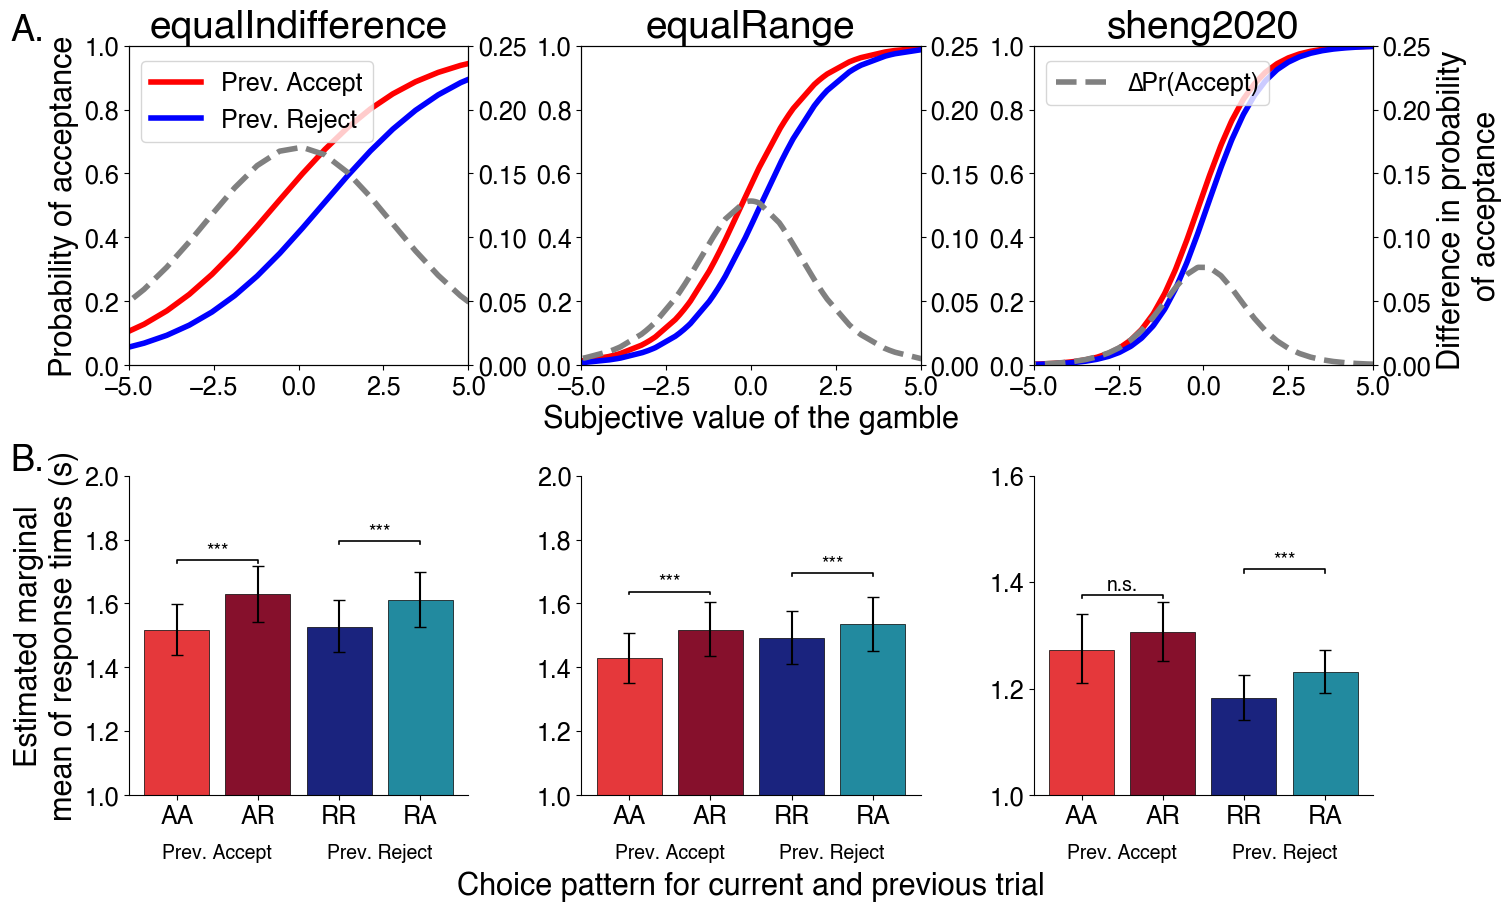

In [54]:
LINE_WIDTH = 4

# AA/AR/RR/RA = (previous choice, current choice): AA=accept_repeat,
# AR=accept_switch, RR=reject_repeat, RA=reject_switch. First two are
# Prev. Accept trials, last two are Prev. Reject trials.
BAR_ORDER = ["accept_repeat", "accept_switch", "reject_repeat", "reject_switch"]
BAR_COLORS = {
    "accept_repeat": "#E5383B",
    "accept_switch": "#86102C",
    "reject_repeat": "#1A237E",
    "reject_switch": "#228A9F",
}

BAR_LABELS = {
    "accept_repeat": "AA",
    "accept_switch": "AR",
    "reject_repeat": "RR",
    "reject_switch": "RA",
}
# (x1, x2, label_a, label_b), shortest span last so the widest bracket stacks
# on top of the others.
BRACKET_PAIRS = [
    (0, 1, "accept_repeat", "accept_switch"),  # AA vs AR: within Prev. Accept
    (2, 3, "reject_repeat", "reject_switch"),  # RR vs RA: within Prev. Reject
]

model2_params = (
    load_fixed_effects()
    .query("model == 'M2_part1_rnd'")
    .pivot(index="dataset", columns="term", values="estimate")
    .rename(columns={
        "(Intercept)": "beta_intercept",
        "gain_centered": "beta_gain",
        "loss_centered": "beta_loss",
        "choice_prev1": "beta_choice_prev1",
    })
)

rtlme_interaction_emmeans = load_rtlme_interaction_emmeans()
rtlme_interaction_contrasts = load_rtlme_interaction_contrasts()

fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(15, 9), layout="constrained")

for col, ds in enumerate(DATASETS):
    # --- Row 1: psychometric curves ---
    ax = axes[0, col]
    params = model2_params.loc[ds]
    sv_grid = compute_sv_grid(ds, params)

    p_prev_accept = sigmoid(params["beta_gain"] * sv_grid + params["beta_choice_prev1"])
    p_prev_reject = sigmoid(params["beta_gain"] * sv_grid - params["beta_choice_prev1"])
    delta = p_prev_accept - p_prev_reject

    ax.plot(sv_grid, p_prev_accept, color="red", linewidth=LINE_WIDTH, label="Prev. Accept")
    ax.plot(sv_grid, p_prev_reject, color="blue", linewidth=LINE_WIDTH, label="Prev. Reject")
    ax.set_xlim(-5, 5)
    ax.set_ylim(0, 1)
    ax.set_title(DATASET_LABELS.get(ds, ds))
    if col == 1:
        ax.set_xlabel("Subjective value of the gamble")

    ax2 = ax.twinx()
    ax2.plot(sv_grid, delta, color="gray", linestyle="--", linewidth=LINE_WIDTH, label="∆Pr(Accept)")
    ax2.set_ylim(0, 0.25)

    if col == 0:
        ax.set_ylabel("Probability of acceptance")
        ax.legend(loc="upper left", bbox_to_anchor=(0, 0.99))
    if col == len(DATASETS) - 1:
        ax2.set_ylabel("Difference in probability \nof acceptance")
        ax2.legend(loc="upper left", bbox_to_anchor=(0, 0.99))

    # --- Row 2: RT LME estimated marginal means ---
    ax_rt = axes[1, col]
    x_pos = np.arange(len(BAR_ORDER))
    vals = [get_condition_emmeans(rtlme_interaction_emmeans, ds, key) for key in BAR_ORDER]
    means = [v[0] for v in vals]
    los = [v[1] for v in vals]
    his = [v[2] for v in vals]
    yerr = [np.array(means) - np.array(los), np.array(his) - np.array(means)]
    colors = [BAR_COLORS[key] for key in BAR_ORDER]

    ax_rt.bar(x_pos, means, yerr=yerr, color=colors, capsize=4,
             edgecolor="black", linewidth=0.5, zorder=2)

    y_max = max(his)
    bracket_h = 0.005 * y_max
    n_tiers = len(BRACKET_PAIRS)
    for tier, (x1, x2, label_a, label_b) in enumerate(BRACKET_PAIRS):
        p_val = get_condition_contrast_pvalue(rtlme_interaction_contrasts, ds, label_a, label_b)
        y_bracket = y_max + (0.005 + 0.035 * tier) * y_max
        add_significance_bracket(ax_rt, x1, x2, y_bracket, bracket_h, p_val)

    ylim_top = 2
    if ds == "sheng2020":
        ylim_top = 1.6
    ax_rt.set_ylim(1, ylim_top)

    ax_rt.set_xticks(x_pos)
    ax_rt.set_xticklabels([BAR_LABELS[key] for key in BAR_ORDER])
    ax_rt.spines["top"].set_visible(False)
    ax_rt.spines["right"].set_visible(False)

    # Group labels below the x-axis: first two bars = Prev. Accept trials,
    # last two = Prev. Reject trials (x in data coords, y in axes fraction).
    ax_rt.text(0.5, -0.15, "Prev. Accept", transform=ax_rt.get_xaxis_transform(),
              ha="center", va="top")
    ax_rt.text(2.5, -0.15, "Prev. Reject", transform=ax_rt.get_xaxis_transform(),
              ha="center", va="top")

    if col == 0:
        ax_rt.set_ylabel("Estimated marginal\nmean of response times (s)")
    if col == 1:
        ax_rt.set_xlabel("Choice pattern for current and previous trial", labelpad=30)

# Row labels, placed just outside the top-left corner of each row's leftmost
# panel (same convention as figure1.ipynb's "A."/"B."/"C.")
axes[0, 0].text(-0.25, 1.1, "A.", transform=axes[0, 0].transAxes,
               fontsize=26, fontweight="bold", va="top", ha="right")
axes[1, 0].text(-0.25, 1.1, "B.", transform=axes[1, 0].transAxes,
               fontsize=26, fontweight="bold", va="top", ha="right")
fig.savefig("saved/figure2.svg", dpi=300, bbox_inches="tight")
plt.show()